In [ ]:
# CT reconstruction: projection count comparison
import sys, platform, json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from skimage.data import shepp_logan_phantom
from skimage.transform import resize, radon, iradon
from skimage.metrics import structural_similarity
from IPython.display import display, Markdown

display(Markdown("""# CT 촬영 각도 수에 따른 영상 재구성 품질 비교
**박지성 · 바이오메디컬공학 · 개인 학습 실습 (AI 보조)**

**질문:** 0–180° 범위에서 균일하게 측정하는 투영 개수가 달라지면 FBP 복원 영상은 어떻게 달라질까?

**조건:** 256×256 Shepp–Logan 가상 팬텀, 30·60·90·180개 투영, 평행빔 Radon 변환, 동일한 ramp 필터 FBP. 잡음은 추가하지 않는다. 각도 범위는 고정하고 표본 개수만 바꾼다.

**비교:** 원본과 재구성 영상을 동일한 밝기 범위로 표시하고, 전체 영상 RMSE·SSIM 및 원형 시야 내부 RMSE를 계산한다. 재구성값을 자르거나 조건별로 정규화하지 않는다.

**참고:** [scikit-image 공식 CT 재구성 예제](https://scikit-image.org/docs/stable/auto_examples/transform/plot_radon_transform.html). 예제를 바탕으로 투영 개수 비교, 고정 시각화 범위, 정량 평가와 결과 저장을 추가했다. 팬텀은 가상 영상이며 환자 데이터가 아니다.
"""))
versions={"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"scikit_image":skimage.__version__}
print("Environment:",versions)

# CT 촬영 각도 수에 따른 영상 재구성 품질 비교
**박지성 · 바이오메디컬공학 · 개인 학습 실습 (AI 보조)**

**질문:** 0–180° 범위에서 균일하게 측정하는 투영 개수가 달라지면 FBP 복원 영상은 어떻게 달라질까?

**조건:** 256×256 Shepp–Logan 가상 팬텀, 30·60·90·180개 투영, 평행빔 Radon 변환, 동일한 ramp 필터 FBP. 잡음은 추가하지 않는다. 각도 범위는 고정하고 표본 개수만 바꾼다.

**비교:** 원본과 재구성 영상을 동일한 밝기 범위로 표시하고, 전체 영상 RMSE·SSIM 및 원형 시야 내부 RMSE를 계산한다. 재구성값을 자르거나 조건별로 정규화하지 않는다.

**참고:** [scikit-image 공식 CT 재구성 예제](https://scikit-image.org/docs/stable/auto_examples/transform/plot_radon_transform.html). 예제를 바탕으로 투영 개수 비교, 고정 시각화 범위, 정량 평가와 결과 저장을 추가했다. 팬텀은 가상 영상이며 환자 데이터가 아니다.


Environment: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit_image': '0.25.2'}


In [ ]:
# 1. Controlled experiment: identical phantom / FBP settings
SIZE=256
COUNTS=[30,60,90,180]
phantom=resize(shepp_logan_phantom(),(SIZE,SIZE),mode="reflect",anti_aliasing=True,preserve_range=True).astype(np.float64)
yy,xx=np.ogrid[:SIZE,:SIZE]
roi=(xx-SIZE//2)**2+(yy-SIZE//2)**2 <= (SIZE//2)**2
phantom[~roi]=0.0
DATA_RANGE=1.0
assert phantom.shape==(SIZE,SIZE) and np.isfinite(phantom).all()
assert phantom.min()>=0 and phantom.max()<=1
results={}
rows=[]
for n in COUNTS:
    theta=np.linspace(0.0,180.0,n,endpoint=False)
    sino=radon(phantom,theta=theta,circle=True,preserve_range=True)
    recon=iradon(sino,theta=theta,output_size=SIZE,filter_name="ramp",interpolation="linear",circle=True,preserve_range=True)
    error=recon-phantom
    assert recon.shape==phantom.shape and np.isfinite(recon).all()
    results[n]={"theta":theta,"sinogram":sino,"reconstruction":recon,"error":error}
    rows.append({"projections":n,"angle_step_deg":180.0/n,"rmse_full":float(np.sqrt(np.mean(error**2))),"ssim_full":float(structural_similarity(phantom,recon,data_range=DATA_RANGE)),"rmse_circle":float(np.sqrt(np.mean(error[roi]**2)))})
metrics=pd.DataFrame(rows)
display(Markdown("## 1. 실험 결과표\nRMSE는 작을수록, SSIM은 클수록 원본과 가깝다. SSIM은 `data_range=1.0`으로 고정했다. 원형 시야 밖의 0 영역 영향을 확인하도록 원형 내부 RMSE도 함께 계산했다."))
display(metrics.round(6))
print("Validation passed: 4 finite reconstructions; fixed phantom, angle range and reconstruction parameters.")

## 1. 실험 결과표
RMSE는 작을수록, SSIM은 클수록 원본과 가깝다. SSIM은 `data_range=1.0`으로 고정했다. 원형 시야 밖의 0 영역 영향을 확인하도록 원형 내부 RMSE도 함께 계산했다.

,projections,angle_step_deg,rmse_full,ssim_full,rmse_circle
0,30,6.0,0.103957,0.463478,0.117349
1,60,3.0,0.046081,0.626668,0.052018
2,90,2.0,0.034536,0.762179,0.038985
3,180,1.0,0.028925,0.921829,0.032651


Validation passed: 4 finite reconstructions; fixed phantom, angle range and reconstruction parameters.


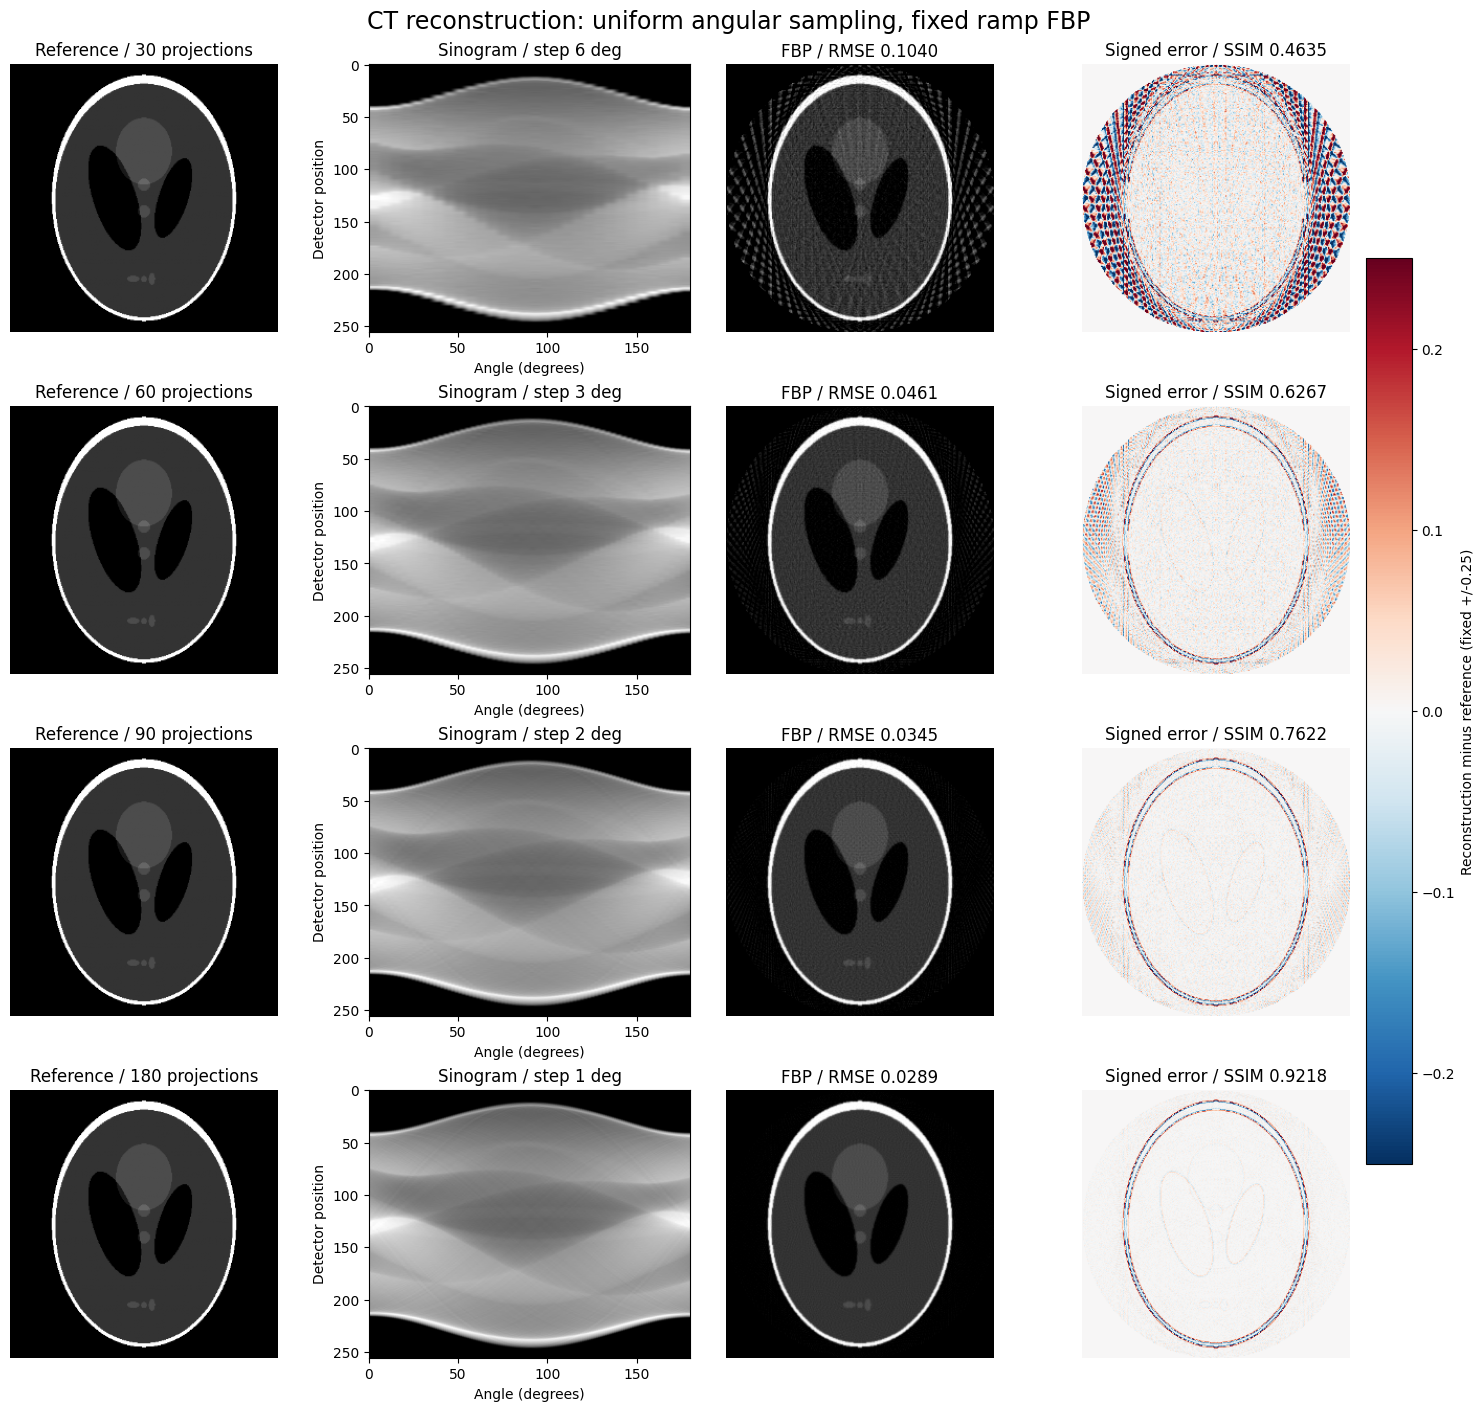

**그림 읽기:** 모든 원본·복원 영상은 밝기 범위 0–1, 오차 영상은 −0.25–0.25로 고정했다. 색상 범위를 벗어나는 오차는 포화되어 보일 수 있다. 표시 범위는 계산값을 변경하지 않는다.

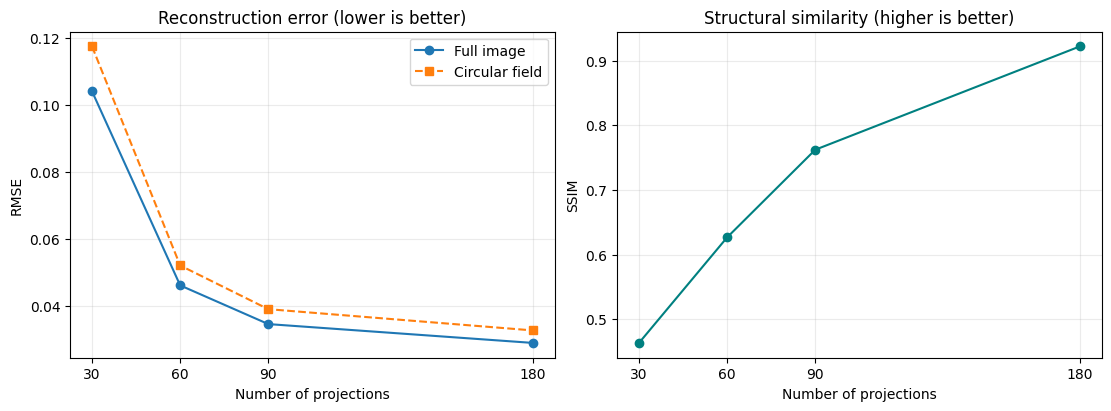

In [ ]:
# 2. Comparable visualizations and reusable figure files
OUT=Path("ct_angle_comparison_outputs")
OUT.mkdir(exist_ok=True)
fig,axes=plt.subplots(4,4,figsize=(15,14),constrained_layout=True)
sino_max=max(v["sinogram"].max() for v in results.values())
ERROR_LIM=0.25
for row,n in enumerate(COUNTS):
    d=results[n]
    axes[row,0].imshow(phantom,cmap="gray",vmin=0,vmax=1)
    axes[row,0].set_title(f"Reference / {n} projections")
    axes[row,1].imshow(d["sinogram"],cmap="gray",vmin=0,vmax=sino_max,aspect="auto",extent=(0,180,SIZE-0.5,-0.5))
    axes[row,1].set_title(f"Sinogram / step {180/n:g} deg")
    axes[row,1].set_xlabel("Angle (degrees)")
    axes[row,1].set_ylabel("Detector position")
    axes[row,2].imshow(d["reconstruction"],cmap="gray",vmin=0,vmax=1)
    axes[row,2].set_title(f"FBP / RMSE {metrics.iloc[row].rmse_full:.4f}")
    err=axes[row,3].imshow(d["error"],cmap="RdBu_r",vmin=-ERROR_LIM,vmax=ERROR_LIM)
    axes[row,3].set_title(f"Signed error / SSIM {metrics.iloc[row].ssim_full:.4f}")
    for j in (0,2,3): axes[row,j].axis("off")
fig.colorbar(err,ax=axes[:,3],shrink=0.7,label="Reconstruction minus reference (fixed +/-0.25)")
fig.suptitle("CT reconstruction: uniform angular sampling, fixed ramp FBP",fontsize=17)
fig.savefig(OUT/"reconstruction_comparison.png",dpi=180,bbox_inches="tight")
plt.show()
display(Markdown("**그림 읽기:** 모든 원본·복원 영상은 밝기 범위 0–1, 오차 영상은 −0.25–0.25로 고정했다. 색상 범위를 벗어나는 오차는 포화되어 보일 수 있다. 표시 범위는 계산값을 변경하지 않는다."))
fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
ax[0].plot(metrics.projections,metrics.rmse_full,"o-",label="Full image")
ax[0].plot(metrics.projections,metrics.rmse_circle,"s--",label="Circular field")
ax[0].set(xlabel="Number of projections",ylabel="RMSE",title="Reconstruction error (lower is better)")
ax[0].legend()
ax[1].plot(metrics.projections,metrics.ssim_full,"o-",color="teal")
ax[1].set(xlabel="Number of projections",ylabel="SSIM",title="Structural similarity (higher is better)")
for a in ax: a.grid(alpha=0.25);a.set_xticks(COUNTS)
fig.savefig(OUT/"quality_metrics.png",dpi=180,bbox_inches="tight")
plt.show()

In [ ]:
# 3. Data-dependent interpretation and export
first=metrics.iloc[0]
last=metrics.iloc[-1]
reduction=(1-last.rmse_full/first.rmse_full)*100
summary=f"""## 3. 결과 해석
- 30개 투영: RMSE **{first.rmse_full:.6f}**, SSIM **{first.ssim_full:.6f}**.
- 180개 투영: RMSE **{last.rmse_full:.6f}**, SSIM **{last.ssim_full:.6f}**.
- 30개 대비 180개의 전체 영상 RMSE 변화: **{reduction:.2f}% 감소**.
- 각도 범위·팬텀·복원 방법을 고정한 이 실험에서는 투영 개수 변화와 영상 품질의 관계를 비교할 수 있다. 줄무늬와 경계 오차는 위 복원·오차 영상에서 함께 확인한다.

### 한계와 다음 실험
잡음 없는 2D 평행빔 팬텀 실험이다. 환자 움직임, 산란, 빔 경화, 실제 검출기, 임상 프로토콜은 포함하지 않는다. 투영 개수만으로 환자 방사선량이나 임상적 유용성을 판단할 수 없다. 전체 영상 SSIM에는 원형 시야 밖의 0 영역도 포함되므로 평가 범위를 함께 명시했다.

다음에는 **고정된 난수 시드로 투영 잡음을 추가하고, ramp와 hann 필터를 비교**한다. 이번 실험과 변수를 섞지 않고 별도 실험으로 기록한다.

### 제작 및 기여 기록
개인 학습 실습이며 AI 보조로 코드·설명·검증 항목을 작성했다. 비교 조건 설정, 결과 확인과 해석 검토는 실습자가 직접 수행할 항목이다. 공식 예제의 출처를 남기며, 실제로 확인하지 않은 경험이나 임상 성과를 주장하지 않는다.
"""
display(Markdown(summary))
metrics.to_csv(OUT/"metrics.csv",index=False)
(OUT/"interpretation.md").write_text(summary,encoding="utf-8")
config={"image_size":SIZE,"projection_counts":COUNTS,"angle_range_deg":[0,180],"endpoint":False,"phantom":"Shepp-Logan synthetic phantom","filter":"ramp","interpolation":"linear","circle":True,"added_noise":False,"ssim_data_range":DATA_RANGE,"versions":versions,"reference":"https://scikit-image.org/docs/stable/auto_examples/transform/plot_radon_transform.html"}
(OUT/"experiment_config.json").write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding="utf-8")
np.savez_compressed(OUT/"experiment_arrays.npz",reference=phantom,**{f"reconstruction_{n}":results[n]["reconstruction"] for n in COUNTS})
archive=Path("ct_angle_comparison_outputs.zip")
with zipfile.ZipFile(archive,"w",zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUT.iterdir()): z.write(path,arcname=path.name)
print("Exported:")
for path in sorted(OUT.iterdir()): print(f"  {path.name}: {path.stat().st_size:,} bytes")
print(f"ZIP: {archive.resolve()} ({archive.stat().st_size:,} bytes)")
print("Metrics JSON:",metrics.to_json(orient="records"))

## 3. 결과 해석
- 30개 투영: RMSE **0.103957**, SSIM **0.463478**.
- 180개 투영: RMSE **0.028925**, SSIM **0.921829**.
- 30개 대비 180개의 전체 영상 RMSE 변화: **72.18% 감소**.
- 각도 범위·팬텀·복원 방법을 고정한 이 실험에서는 투영 개수 변화와 영상 품질의 관계를 비교할 수 있다. 줄무늬와 경계 오차는 위 복원·오차 영상에서 함께 확인한다.

### 한계와 다음 실험
잡음 없는 2D 평행빔 팬텀 실험이다. 환자 움직임, 산란, 빔 경화, 실제 검출기, 임상 프로토콜은 포함하지 않는다. 투영 개수만으로 환자 방사선량이나 임상적 유용성을 판단할 수 없다. 전체 영상 SSIM에는 원형 시야 밖의 0 영역도 포함되므로 평가 범위를 함께 명시했다.

다음에는 **고정된 난수 시드로 투영 잡음을 추가하고, ramp와 hann 필터를 비교**한다. 이번 실험과 변수를 섞지 않고 별도 실험으로 기록한다.

### 제작 및 기여 기록
개인 학습 실습이며 AI 보조로 코드·설명·검증 항목을 작성했다. 비교 조건 설정, 결과 확인과 해석 검토는 실습자가 직접 수행할 항목이다. 공식 예제의 출처를 남기며, 실제로 확인하지 않은 경험이나 임상 성과를 주장하지 않는다.


Exported:
  experiment_arrays.npz: 1,605,691 bytes
  experiment_config.json: 537 bytes
  interpretation.md: 1,341 bytes
  metrics.csv: 326 bytes
  quality_metrics.png: 95,672 bytes
  reconstruction_comparison.png: 3,145,289 bytes
ZIP: /content/ct_angle_comparison_outputs.zip (4,805,054 bytes)
Metrics JSON: [{"projections":30,"angle_step_deg":6.0,"rmse_full":0.1039569423,"ssim_full":0.4634776592,"rmse_circle":0.1173494283},{"projections":60,"angle_step_deg":3.0,"rmse_full":0.0460812664,"ssim_full":0.6266681851,"rmse_circle":0.0520177887},{"projections":90,"angle_step_deg":2.0,"rmse_full":0.0345361986,"ssim_full":0.7621790113,"rmse_circle":0.0389854018},{"projections":180,"angle_step_deg":1.0,"rmse_full":0.0289247444,"ssim_full":0.9218288275,"rmse_circle":0.0326510394}]
